<a href="https://colab.research.google.com/github/alejandrohw30-code/MAESTRIA/blob/main/Tarea3_codigos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

plt.rcParams.update({"font.family": "serif", "mathtext.fontset": "cm", "font.size": 10})

## Ejercicio 2 — Curvas de nivel y recta $P_1P_2$

$f(x,y)=x^2+xy+y^2+3x$. Mínimo analítico: $(-2,1)$, $f^*=-3$. Niveles elegidos: $c=-2,0,3,6$.

In [ ]:
# (a) Comprobación simbólica del mínimo
x, y = sp.symbols("x y")
f2 = x**2 + x*y + y**2 + 3*x
sol = sp.solve([sp.diff(f2, x), sp.diff(f2, y)], [x, y], dict=True)[0]
print("punto critico:", sol, " f* =", f2.subs(sol))
print("Hessiana:", sp.hessian(f2, (x, y)), " autovalores:", sp.hessian(f2, (x, y)).eigenvals())

punto critico: {x: -2, y: 1}  f* = -3
Hessiana: Matrix([[2, 1], [1, 2]])  autovalores: {3: 1, 1: 1}


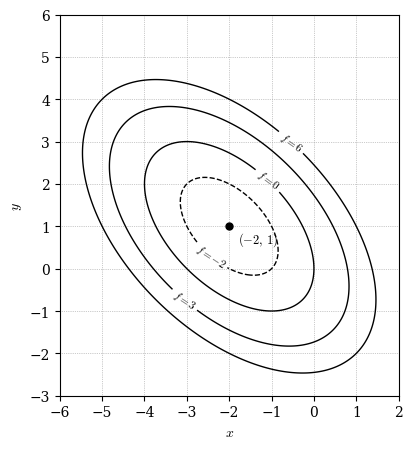

P1 = (-1.5, 0.0)  P2 = (-3.5, 4.0)


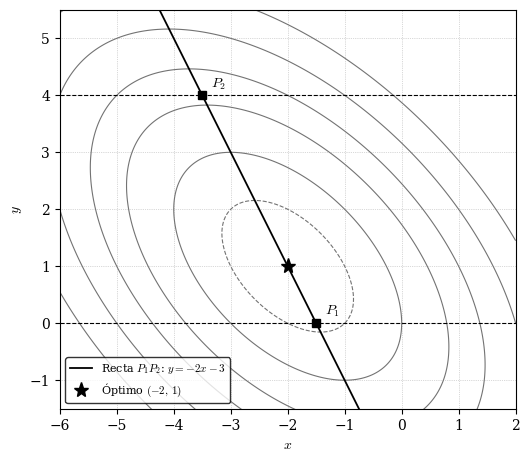

In [ ]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

plt.rcParams.update({"font.family": "serif", "mathtext.fontset": "cm", "font.size": 10})

# f(x,y) = x^2 + xy + y^2 + 3x
f = lambda X, Y: X**2 + X*Y + Y**2 + 3*X
X, Y = np.meshgrid(np.linspace(-6, 2, 500), np.linspace(-3, 6, 500))
Z = f(X, Y)

# ---- Figura 1: cuatro curvas de nivel f = -2, 0, 3, 6 ----
fig, ax = plt.subplots(figsize=(5.2, 4.6))
cs = ax.contour(X, Y, Z, levels=[-2, 0, 3, 6], colors="black", linewidths=1.0)
ax.clabel(cs, fmt=lambda l: f"$f={l:g}$", fontsize=8)
ax.plot(-2, 1, "ko", ms=5)
ax.annotate(r"$(-2,\,1)$", (-2, 1), textcoords="offset points", xytext=(6, -12), fontsize=9)
ax.set_xlabel("$x$"); ax.set_ylabel("$y$"); ax.set_aspect("equal")
ax.grid(True, ls=":", lw=0.5, color="0.6")
fig.tight_layout(); fig.savefig("fig_niveles.pdf"); plt.show()

# ---- Optimos P1 y P2 sobre y=0 y y=4 (direccion s=[1,0]) ----
x, y, a = sp.symbols("x y a")
f2 = x**2 + x*y + y**2 + 3*x
a1 = sp.solve(sp.diff(f2.subs({x: a, y: 0}), a), a)[0]
a2 = sp.solve(sp.diff(f2.subs({x: a, y: 4}), a), a)[0]
P1, P2 = (float(a1), 0.0), (float(a2), 4.0)
print("P1 =", P1, " P2 =", P2)

# ---- Figura 2: recta que une P1 y P2 ----
fig, ax = plt.subplots(figsize=(5.4, 4.8))
ax.contour(X, Y, Z, levels=[-2, 0, 3, 6, 10, 15], colors="0.45", linewidths=0.8)
xs = np.linspace(-5.0, 0.2, 50)
ax.plot(xs, -2*xs - 3, "k-", lw=1.3, label=r"Recta $P_1P_2$: $y=-2x-3$")
ax.plot([P1[0], P2[0]], [P1[1], P2[1]], "ks", ms=6)
ax.plot([-6, 2], [0, 0], "k--", lw=0.8); ax.plot([-6, 2], [4, 4], "k--", lw=0.8)
ax.plot(-2, 1, "k*", ms=11, label=r"Óptimo $(-2,\,1)$")
ax.annotate(r"$P_1$", P1, textcoords="offset points", xytext=(6, 6))
ax.annotate(r"$P_2$", P2, textcoords="offset points", xytext=(6, 6))
ax.set_xlim(-6, 2); ax.set_ylim(-1.5, 5.5); ax.set_xlabel("$x$"); ax.set_ylabel("$y$")
ax.set_aspect("equal"); ax.legend(loc="lower left", fontsize=8, edgecolor="black")
ax.grid(True, ls=":", lw=0.5, color="0.7")
fig.tight_layout(); fig.savefig("fig_recta.pdf"); plt.show()

## Ejercicio 6 — Newton y quasi-Newton (BFGS)

Modelo (con las constantes agrupadas $K_0, A_1,\dots,A_7$), gradiente y Hessiana analíticos.

In [ ]:
import numpy as np
from scipy.optimize import minimize

# ---------- Parametros del problema (el ultimo termino de A2 sigue el enunciado: sin "a") ----------
a, cc, ci, cx, i_, n, p = 0.20, 12.5, 0.50, 0.90, 0.10, 2, 7000.0
D = 52.47 * 360.0
K0 = cc + ci + cx
A1 = 2.09e4 / 360.0
A2 = 1.064e6 / D
A3 = 4.242e4 * a / D
A4 = 1.813 * i_ * p / D
A5 = 4.25e3 * a / D
A6 = 5.042e3 / 360.0
A7 = 0.1049 / 360.0

def N(q, t):                       # N = n t + 1.2 q
    return n * t + 1.2 * q

def c(v):
    q, t = v
    Nn = N(q, t)
    return (K0 + A1 * t**-0.3017 + A2 * t**0.4925 / q + A3 * t**0.7952 / q
            + A4 * Nn**0.861 / q + A5 * Nn / q + A6 * q**-0.1899 + A7 * q**0.671)

def grad(v):                       # gradiente analitico (c_q, c_t)
    q, t = v
    Nn = N(q, t)
    cq = (-A2 * t**0.4925 / q**2 - A3 * t**0.7952 / q**2
          + A4 * (1.0332 * Nn**-0.139 / q - Nn**0.861 / q**2)
          - 2 * A5 * t / q**2 - 0.1899 * A6 * q**-1.1899 + 0.671 * A7 * q**-0.329)
    ct = (-0.3017 * A1 * t**-1.3017 + 0.4925 * A2 * t**-0.5075 / q
          + 0.7952 * A3 * t**-0.2048 / q + 2 * 0.861 * A4 * Nn**-0.139 / q + 2 * A5 / q)
    return np.array([cq, ct])

def hess(v):                       # Hessiana analitica
    q, t = v
    Nn = N(q, t)
    cqq = (2 * A2 * t**0.4925 / q**3 + 2 * A3 * t**0.7952 / q**3
           + A4 * (1.0332 * (-0.139) * 1.2 * Nn**-1.139 / q - 2 * 1.0332 * Nn**-0.139 / q**2
                   + 2 * Nn**0.861 / q**3)
           + 4 * A5 * t / q**3 + 0.1899 * 1.1899 * A6 * q**-2.1899
           - 0.329 * 0.671 * A7 * q**-1.329)
    cqt = (-0.4925 * A2 * t**-0.5075 / q**2 - 0.7952 * A3 * t**-0.2048 / q**2
           + A4 * (-2 * 1.0332 * 0.139 * Nn**-1.139 / q - 2 * 0.861 * Nn**-0.139 / q**2)
           - 2 * A5 / q**2)
    ctt = (0.3017 * 1.3017 * A1 * t**-2.3017 - 0.4925 * 0.5075 * A2 * t**-1.5075 / q
           - 0.7952 * 0.2048 * A3 * t**-1.2048 / q
           - 4 * 0.861 * 0.139 * A4 * Nn**-1.139 / q)
    return np.array([[cqq, cqt], [cqt, ctt]])

In [ ]:
# Verificacion de gradiente y Hessiana analiticos contra SymPy
q_, t_ = sp.symbols('q t', positive=True)
N_ = n*t_ + sp.Float('1.2')*q_
cs = (K0 + A1*t_**-0.3017 + A2*t_**0.4925/q_ + A3*t_**0.7952/q_ + A4*N_**0.861/q_
      + A5*N_/q_ + A6*q_**-0.1899 + A7*q_**0.671)
v = [2.0e5, 4.0e5]
gs = np.array([float(sp.diff(cs, s).subs({q_: v[0], t_: v[1]})) for s in (q_, t_)])
Hs = np.array(sp.hessian(cs, (q_, t_)).subs({q_: v[0], t_: v[1]}).evalf(), float)
print('error relativo gradiente:', np.abs(gs - grad(v)).max() / np.abs(gs).max())
print('error relativo Hessiana :', np.abs(Hs - hess(v)).max() / np.abs(Hs).max())

error relativo gradiente: 5.432033950280632e-14
error relativo Hessiana : 2.1267090984486486e-15


In [ ]:
def busqueda_lineal(v, d, g):      # retroceso (Armijo) manteniendo q, t > 0
    s, f0 = 1.0, c(v)
    while True:
        w = v + s * d
        if w.min() > 0 and c(w) <= f0 + 1e-4 * s * (g @ d):
            return s
        s *= 0.5

def newton(v0, tol=1e-13, maxit=100):
    v = np.array(v0, float); hist = []
    for k in range(maxit):
        g, H = grad(v), hess(v)
        hist.append((k, v.copy(), c(v), np.linalg.norm(g)))
        if np.linalg.norm(g) < tol: break
        if np.linalg.eigvalsh(H).min() <= 0:          # Hessiana no definida positiva -> modificar
            H = H + (abs(np.linalg.eigvalsh(H).min()) + 1e-12) * np.eye(2)
        d = -np.linalg.solve(H, g)
        v = v + busqueda_lineal(v, d, g) * d
    return v, hist

def bfgs(v0, tol=1e-13, maxit=200):
    v = np.array(v0, float); Hinv = np.linalg.inv(hess(v)); hist = []   # H0 = inversa de la Hessiana inicial
    g = grad(v)
    for k in range(maxit):
        hist.append((k, v.copy(), c(v), np.linalg.norm(g)))
        if np.linalg.norm(g) < tol: break
        d = -Hinv @ g
        s = busqueda_lineal(v, d, g)
        vn = v + s * d; gn = grad(vn)
        sk, yk = vn - v, gn - g
        if sk @ yk > 1e-30:
            rho = 1.0 / (yk @ sk); I = np.eye(2)
            Hinv = (I - rho * np.outer(sk, yk)) @ Hinv @ (I - rho * np.outer(yk, sk)) + rho * np.outer(sk, sk)
        v, g = vn, gn
    return v, hist

In [ ]:
v0 = [1.0e5, 1.0e5]
for nombre, met in (("Newton", newton), ("quasi-Newton (BFGS)", bfgs)):
    v, h = met(v0)
    print(nombre)
    for k, x, f, gn in h:
        print(f"{k:3d}  q={x[0]:14.4f}  t={x[1]:14.4f}  c={f:.8f}  |g|={gn:.3e}")
    q, t = v
    print("optimo: q =", q, "bbl/dia =", q / 6.29, "kL/dia; t =", t, "kL; c =", c(v))
    print("Hessiana en el optimo, autovalores:", np.linalg.eigvalsh(hess(v)))
    print()

from scipy.optimize import minimize
r = minimize(c, v0, jac=grad, method="BFGS", options={"gtol": 1e-14, "maxiter": 500})
print("SciPy BFGS: q =", r.x[0], " t =", r.x[1], " c =", r.fun)

Newton
  0  q=   100000.0000  t=   100000.0000  c=18.32025164  |g|=3.648e-06
  1  q=   136970.9932  t=   161178.0750  c=18.15067368  |g|=1.513e-06
  2  q=   168210.0540  t=   242915.3249  c=18.06607301  |g|=5.982e-07
  3  q=   189164.3472  t=   331140.6049  c=18.03305686  |g|=2.072e-07
  4  q=   200641.1750  t=   396193.0686  c=18.02560510  |g|=4.812e-08
  5  q=   204195.5560  t=   419413.8210  c=18.02507284  |g|=3.983e-09
  6  q=   204502.3885  t=   421556.0733  c=18.02506914  |g|=3.025e-11
  7  q=   204504.6472  t=   421572.2103  c=18.02506914  |g|=1.707e-15
optimo: q = 204504.64719324565 bbl/dia = 32512.662510849863 kL/dia; t = 421572.2102724437 kL; c = 18.02506914177813
Hessiana en el optimo, autovalores: [1.50733661e-12 2.42937523e-11]

quasi-Newton (BFGS)
  0  q=   100000.0000  t=   100000.0000  c=18.32025164  |g|=3.648e-06
  1  q=   136970.9932  t=   161178.0750  c=18.15067368  |g|=1.513e-06
  2  q=   158159.7601  t=   205617.8339  c=18.09424283  |g|=9.075e-07
  3  q=   181992.7